In [26]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
import h5py

import scipp as sc
import matplotlib.colors as colors
import ipywidgets as ipw


import plopp.widgets as pw
import plopp as pp
import mpld3

import pyarrow.parquet as pq
import pyarrow as pa




In [27]:

files = [
    "./crystal1.parquet",
    "./crystal2.parquet",
    "./crystal3.parquet",
]

tables = [pq.read_table(f) for f in files]

table_all = pa.concat_tables(tables, promote_options="default")

df_all = table_all.to_pandas()

In [28]:
deltaE_= df_all['hw'].values 
I_=df_all['Intensity'].values

factor=1
# factor=2*3.14/a
h_ = -df_all['h'].values * factor
k_ = df_all['k'].values 
l_ = df_all['l'].values * factor

deltaE = sc.array(dims=["row"], values=deltaE_, unit="meV")
h = sc.array(dims=["row"], values=h_, unit="Å^(-1)")
k = sc.array(dims=["row"], values=k_, unit="Å^(-1)")
l = sc.array(dims=["row"], values=l_, unit="Å^(-1)")

data = sc.DataArray(
    data=sc.array(dims=["row"], values=I_, unit="arb. units"),
    coords={"deltaE": deltaE,"h": h,"l": l,"k": k}
    )
    

In [29]:
h_step = 0.05
k_step = 0.05
l_step = 0.05
E_step = 0.2

h_bins = int(np.ceil((data.coords['h'].max().value - data.coords['h'].min().value)/h_step))
k_bins = int(np.ceil((data.coords['k'].max().value - data.coords['k'].min().value)/k_step))
l_bins = int(np.ceil((data.coords['l'].max().value - data.coords['l'].min().value)/l_step))

E_bins = int(np.ceil((data.coords['deltaE'].max().value - data.coords['deltaE'].min().value)/E_step))

data_binned=data.bin(l=l_bins, h=h_bins,deltaE=E_bins)
sliced = data_binned.bins.mean()




In [30]:
h_min = -4 * sc.Unit('Å^(-1)')
h_max = 4 * sc.Unit('Å^(-1)')

l_min = -4 * sc.Unit('Å^(-1)')
l_max = 4.0 * sc.Unit('Å^(-1)')

def plot(amp):
    E_layer = amp * sc.Unit('meV')
    p1 = sliced['deltaE', E_layer]['l', l_min:l_max]
    im = plt.pcolormesh(p1.coords['h'].values, p1.coords['l'].values, p1.values,
                        vmin=0, vmax=.0001)
    plt.xlabel('$h$ [1/Å]')
    plt.ylabel('$l$ [1/Å]')
    plt.title(f"$\Delta E =$ {amp:.2f} meV")


w = ipw.FloatSlider( 
    min=1.0,
    max=7.0,
    step=0.5,
    description="hw:",
    continuous_update=True,
)

ipw.interactive(plot, amp=4)

<>:14: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:14: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
/tmp/ipykernel_3688147/2205034805.py:14: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  plt.title(f"$\Delta E =$ {amp:.2f} meV")


interactive(children=(IntSlider(value=4, description='amp', max=12, min=-4), Output()), _dom_classes=('widget-…

In [31]:
lE = data.bin(l=l_bins, h=h_bins, deltaE=E_bins)
sliced_lE = lE.bins.mean()

l_min = -2 * sc.Unit('Å^(-1)')
l_max = 2 * sc.Unit('Å^(-1)')
E_min = 0 * sc.Unit('meV')
E_max = 10.0 * sc.Unit('meV')

def plot(h):
    h_layer = h * sc.Unit('Å^(-1)')
    p_E = sliced_lE['h', h_layer]['l', l_min:l_max]['deltaE', E_min:E_max].transpose()

    plt.figure(figsize=(6, 4))
    im = plt.pcolormesh(p_E.coords['l'].values, p_E.coords['deltaE'].values,
                        p_E.values, vmin=0, vmax=0.0001, shading='auto')
    plt.colorbar(im, label='I [a.u.]')
    plt.xlabel('$l$ [1/Å]')
    plt.ylabel(r'$\Delta E$ [meV]')
    plt.title(f'$h$ = {h:.2f} Å$^{{-1}}$')
    plt.tight_layout()
    plt.show()

w = ipw.FloatSlider(
    value=2.0,
    min=-1.5,
    max=2.5,
    step=0.1,
    description='h:',
    continuous_update=True
)

ipw.interactive(plot, h=w)

interactive(children=(FloatSlider(value=2.0, description='h:', max=2.5, min=-1.5), Output()), _dom_classes=('w…

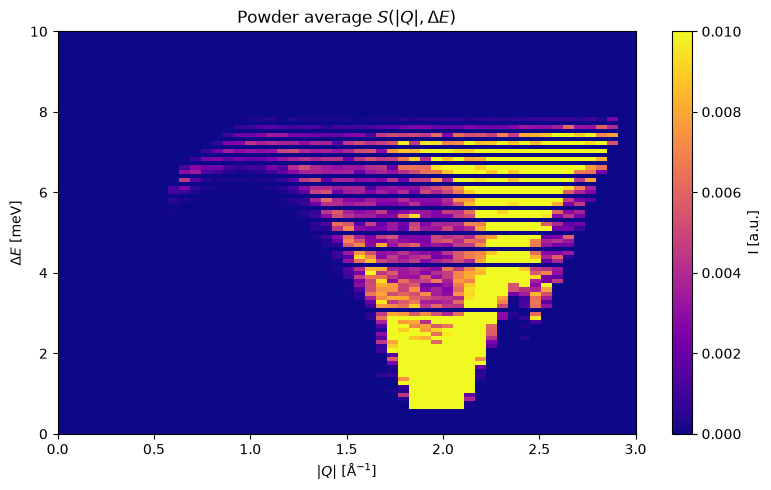

In [32]:
#powder average

data.coords['Q'] = sc.sqrt(data.coords['h']**2 + data.coords['l']**2)

Q_bins = sc.linspace('Q', 0, 5.65, 100, unit='Å^(-1)')
E_bins = sc.linspace('deltaE', 0, 10, 100, unit='meV')

powder = data.bin(Q=Q_bins, deltaE=E_bins).bins.sum()

p = powder.transpose(('deltaE', 'Q'))

# Plot
plt.figure(figsize=(8, 5))
im = plt.pcolormesh(
    p.coords['Q'].values,
    p.coords['deltaE'].values,
    p.values,
    shading='auto',
    cmap='plasma',
    vmin=0,
    vmax=0.01
)

cbar = plt.colorbar(im)
cbar.set_label('I [a.u.]')
plt.xlim(0,3)
plt.xlabel(r'$|Q|$ [$\mathrm{\AA}^{-1}$]')
plt.ylabel(r'$\Delta E$ [meV]')
plt.title(r'Powder average $S(|Q|,\Delta E)$')
plt.tight_layout()
plt.show()